In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

# Thiết lập style biểu đồ
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)

# Đường dẫn dữ liệu raw
data_path = os.path.join('..', 'data', 'raw')
all_files = sorted(glob.glob(os.path.join(data_path, '*.csv')))

olist_data = {}
print('--- ĐANG LOAD DỮ LIỆU ---')
for file_path in all_files:
    file_name = os.path.basename(file_path).replace('.csv', '')
    olist_data[file_name] = pd.read_csv(file_path)
    print(f'✅ Đã load: {file_name} | Kích thước: {olist_data[file_name].shape}')

required_tables = [
    'olist_orders_dataset',
    'olist_order_items_dataset',
    'olist_customers_dataset',
    'olist_products_dataset'
]
missing_tables = [t for t in required_tables if t not in olist_data]
if missing_tables:
    raise FileNotFoundError(f'Không tìm thấy file dữ liệu: {missing_tables}')

# Trích xuất các bảng chính
df_orders = olist_data['olist_orders_dataset']
df_items = olist_data['olist_order_items_dataset']
df_customers = olist_data['olist_customers_dataset']
df_products = olist_data['olist_products_dataset']

# Load translation mapping for category names
translation_path = os.path.join('..', 'data', 'raw', 'product_category_name_translation.csv')
if not os.path.exists(translation_path):
    raise FileNotFoundError(f'Không tìm thấy file dịch danh mục: {translation_path}')
df_category_translation = pd.read_csv(translation_path)
category_translation = dict(
    zip(
        df_category_translation['product_category_name'],
        df_category_translation['product_category_name_english']
    )
)

df_orders['order_purchase_timestamp'] = pd.to_datetime(
    df_orders['order_purchase_timestamp'],
    errors='coerce'
)


--- ĐANG LOAD DỮ LIỆU ---
✅ Đã load: olist_customers_dataset | Kích thước: (99441, 5)
✅ Đã load: olist_geolocation_dataset | Kích thước: (1000163, 5)
✅ Đã load: olist_order_items_dataset | Kích thước: (112650, 7)
✅ Đã load: olist_order_payments_dataset | Kích thước: (103886, 5)
✅ Đã load: olist_order_reviews_dataset | Kích thước: (99224, 7)
✅ Đã load: olist_orders_dataset | Kích thước: (99441, 8)
✅ Đã load: olist_products_dataset | Kích thước: (32951, 9)
✅ Đã load: olist_sellers_dataset | Kích thước: (3095, 4)
✅ Đã load: product_category_name_translation | Kích thước: (71, 2)


In [29]:
def missing_values_table(df):
    mis_val = df.isnull().sum()
    mis_val_percent = 100 * mis_val / len(df)
    mis_val_table = pd.concat(
        [mis_val, mis_val_percent],
        axis=1,
        keys=['Số lượng thiếu', 'Phần trăm (%)']
    )
    return mis_val_table[mis_val_table['Số lượng thiếu'] > 0].sort_values(
        'Phần trăm (%)', ascending=False
    )

print('--- 5 DÒNG ĐẦU BẢNG ORDERS ---')
display(df_orders.head())

print('\n--- THÔNG TIN BẢNG ORDERS ---')
df_orders.info()

print('\n--- TỶ LỆ MISSING VALUES ---')
display(missing_values_table(df_orders))

print(f'\nSố dòng trùng lặp trong Orders: {df_orders.duplicated().sum()}')


--- 5 DÒNG ĐẦU BẢNG ORDERS ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



--- THÔNG TIN BẢNG ORDERS ---
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  str           
 5   order_delivered_carrier_date   97658 non-null  str           
 6   order_delivered_customer_date  96476 non-null  str           
 7   order_estimated_delivery_date  99441 non-null  str           
dtypes: datetime64[us](1), str(7)
memory usage: 6.1 MB

--- TỶ LỆ MISSING VALUES ---


,Số lượng thiếu,Phần trăm (%)
order_delivered_customer_date,2965,2.981668
order_delivered_carrier_date,1783,1.793023
order_approved_at,160,0.160899



Số dòng trùng lặp trong Orders: 0


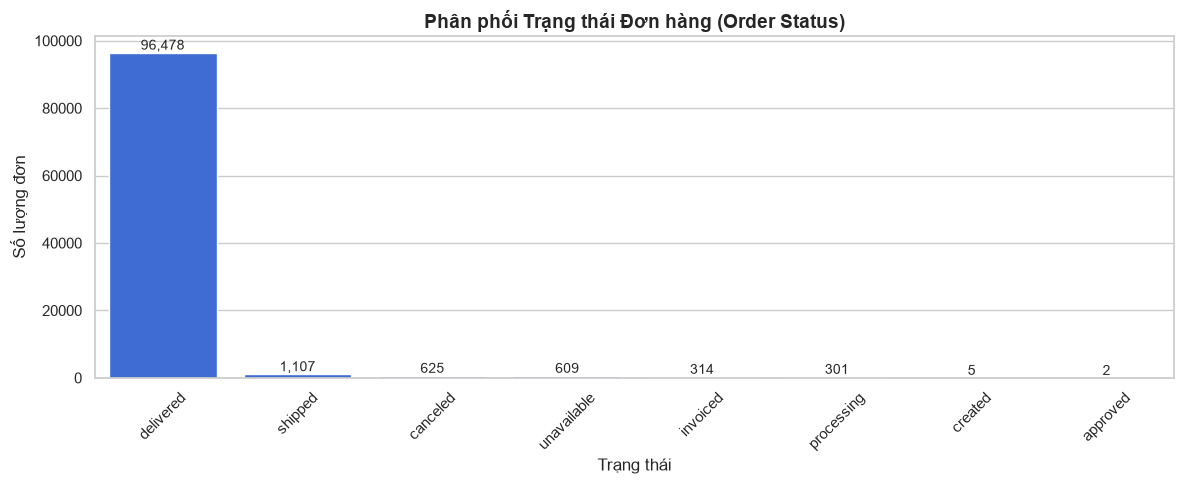

In [30]:
order_status_counts = df_orders['order_status'].value_counts()

plt.figure(figsize=(12, 5))
ax = sns.barplot(
    x=order_status_counts.index,
    y=order_status_counts.values,
    color='#2563EB'
)
for patch in ax.patches:
    ax.annotate(
        f'{int(patch.get_height()):,}',
        (patch.get_x() + patch.get_width() / 2., patch.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Phân phối Trạng thái Đơn hàng (Order Status)', fontsize=14, fontweight='bold')
plt.xlabel('Trạng thái')
plt.ylabel('Số lượng đơn')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


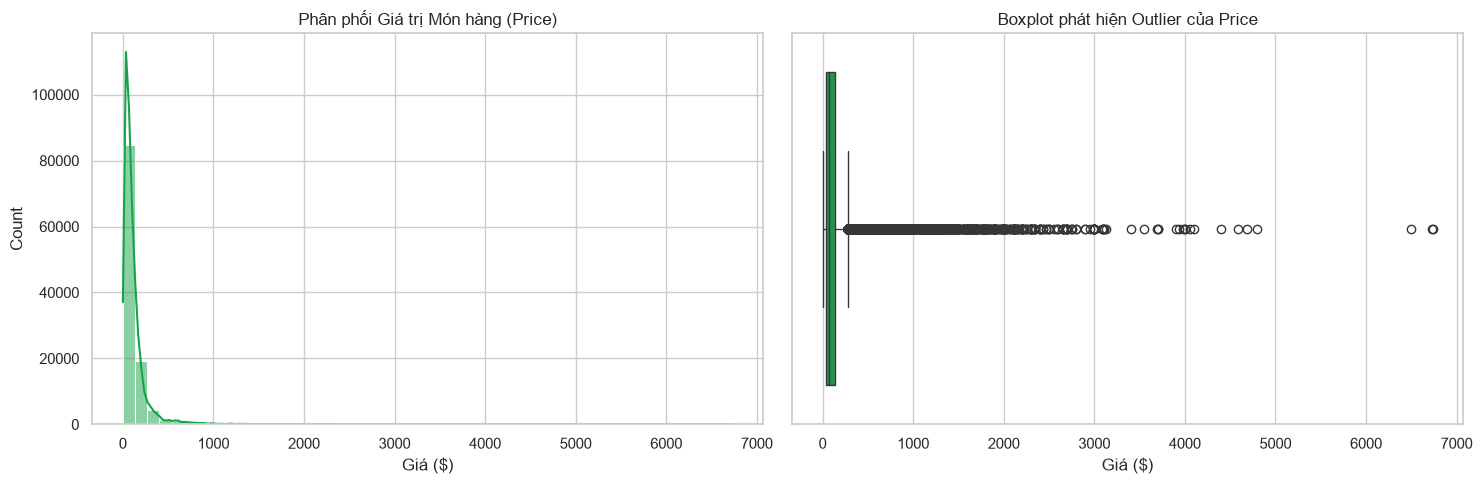

In [31]:
display(df_items[['price', 'freight_value']].describe())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(
    df_items['price'],
    bins=50,
    kde=True,
    ax=axes[0],
    color='#16A34A'
)
axes[0].set_title('Phân phối Giá trị Món hàng (Price)')
axes[0].set_xlabel('Giá ($)')

sns.boxplot(x=df_items['price'], ax=axes[1], color='#16A34A')
axes[1].set_title('Boxplot phát hiện Outlier của Price')
axes[1].set_xlabel('Giá ($)')

plt.tight_layout()
plt.show()


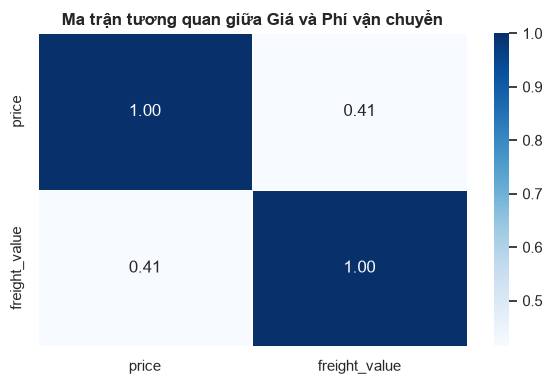

In [32]:
corr_matrix = df_items[['price', 'freight_value']].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='Blues',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Ma trận tương quan giữa Giá và Phí vận chuyển', fontweight='bold')
plt.tight_layout()
plt.show()


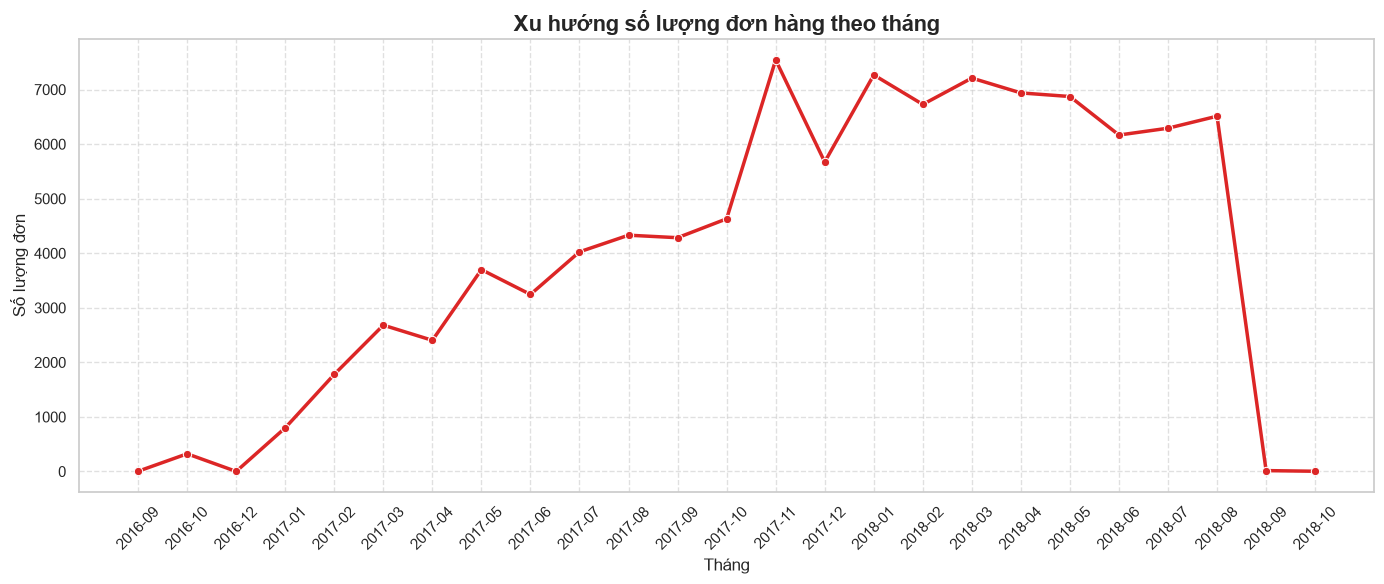

In [33]:
df_orders['YearMonth'] = df_orders['order_purchase_timestamp'].dt.to_period('M')
monthly_orders = (
    df_orders
    .groupby('YearMonth')
    .size()
    .reset_index(name='Total_Orders')
)
monthly_orders['YearMonth'] = monthly_orders['YearMonth'].astype(str)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_orders,
    x='YearMonth',
    y='Total_Orders',
    marker='o',
    linewidth=2.5,
    color='#DC2626'
)
plt.title('Xu hướng số lượng đơn hàng theo tháng', fontsize=16, fontweight='bold')
plt.xlabel('Tháng')
plt.ylabel('Số lượng đơn')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [34]:
df_merged = pd.merge(df_orders, df_items, on='order_id', how='inner')
df_merged = pd.merge(df_merged, df_customers, on='customer_id', how='inner')
df_merged = pd.merge(df_merged, df_products, on='product_id', how='inner')

df_merged['order_purchase_timestamp'] = pd.to_datetime(
    df_merged['order_purchase_timestamp'],
    errors='coerce'
)

# Thống kê tổng quan
total_orders = df_merged['order_id'].nunique()
total_revenue = df_merged['price'].sum()
print('--- CHỈ SỐ KINH DOANH TỔNG QUAN ---')
print(f'Tổng số lượng đơn hàng: {total_orders:,} đơn')
print(f'Tổng doanh thu: ${total_revenue:,.2f}')


--- CHỈ SỐ KINH DOANH TỔNG QUAN ---
Tổng số lượng đơn hàng: 98,666 đơn
Tổng doanh thu: $13,591,643.70


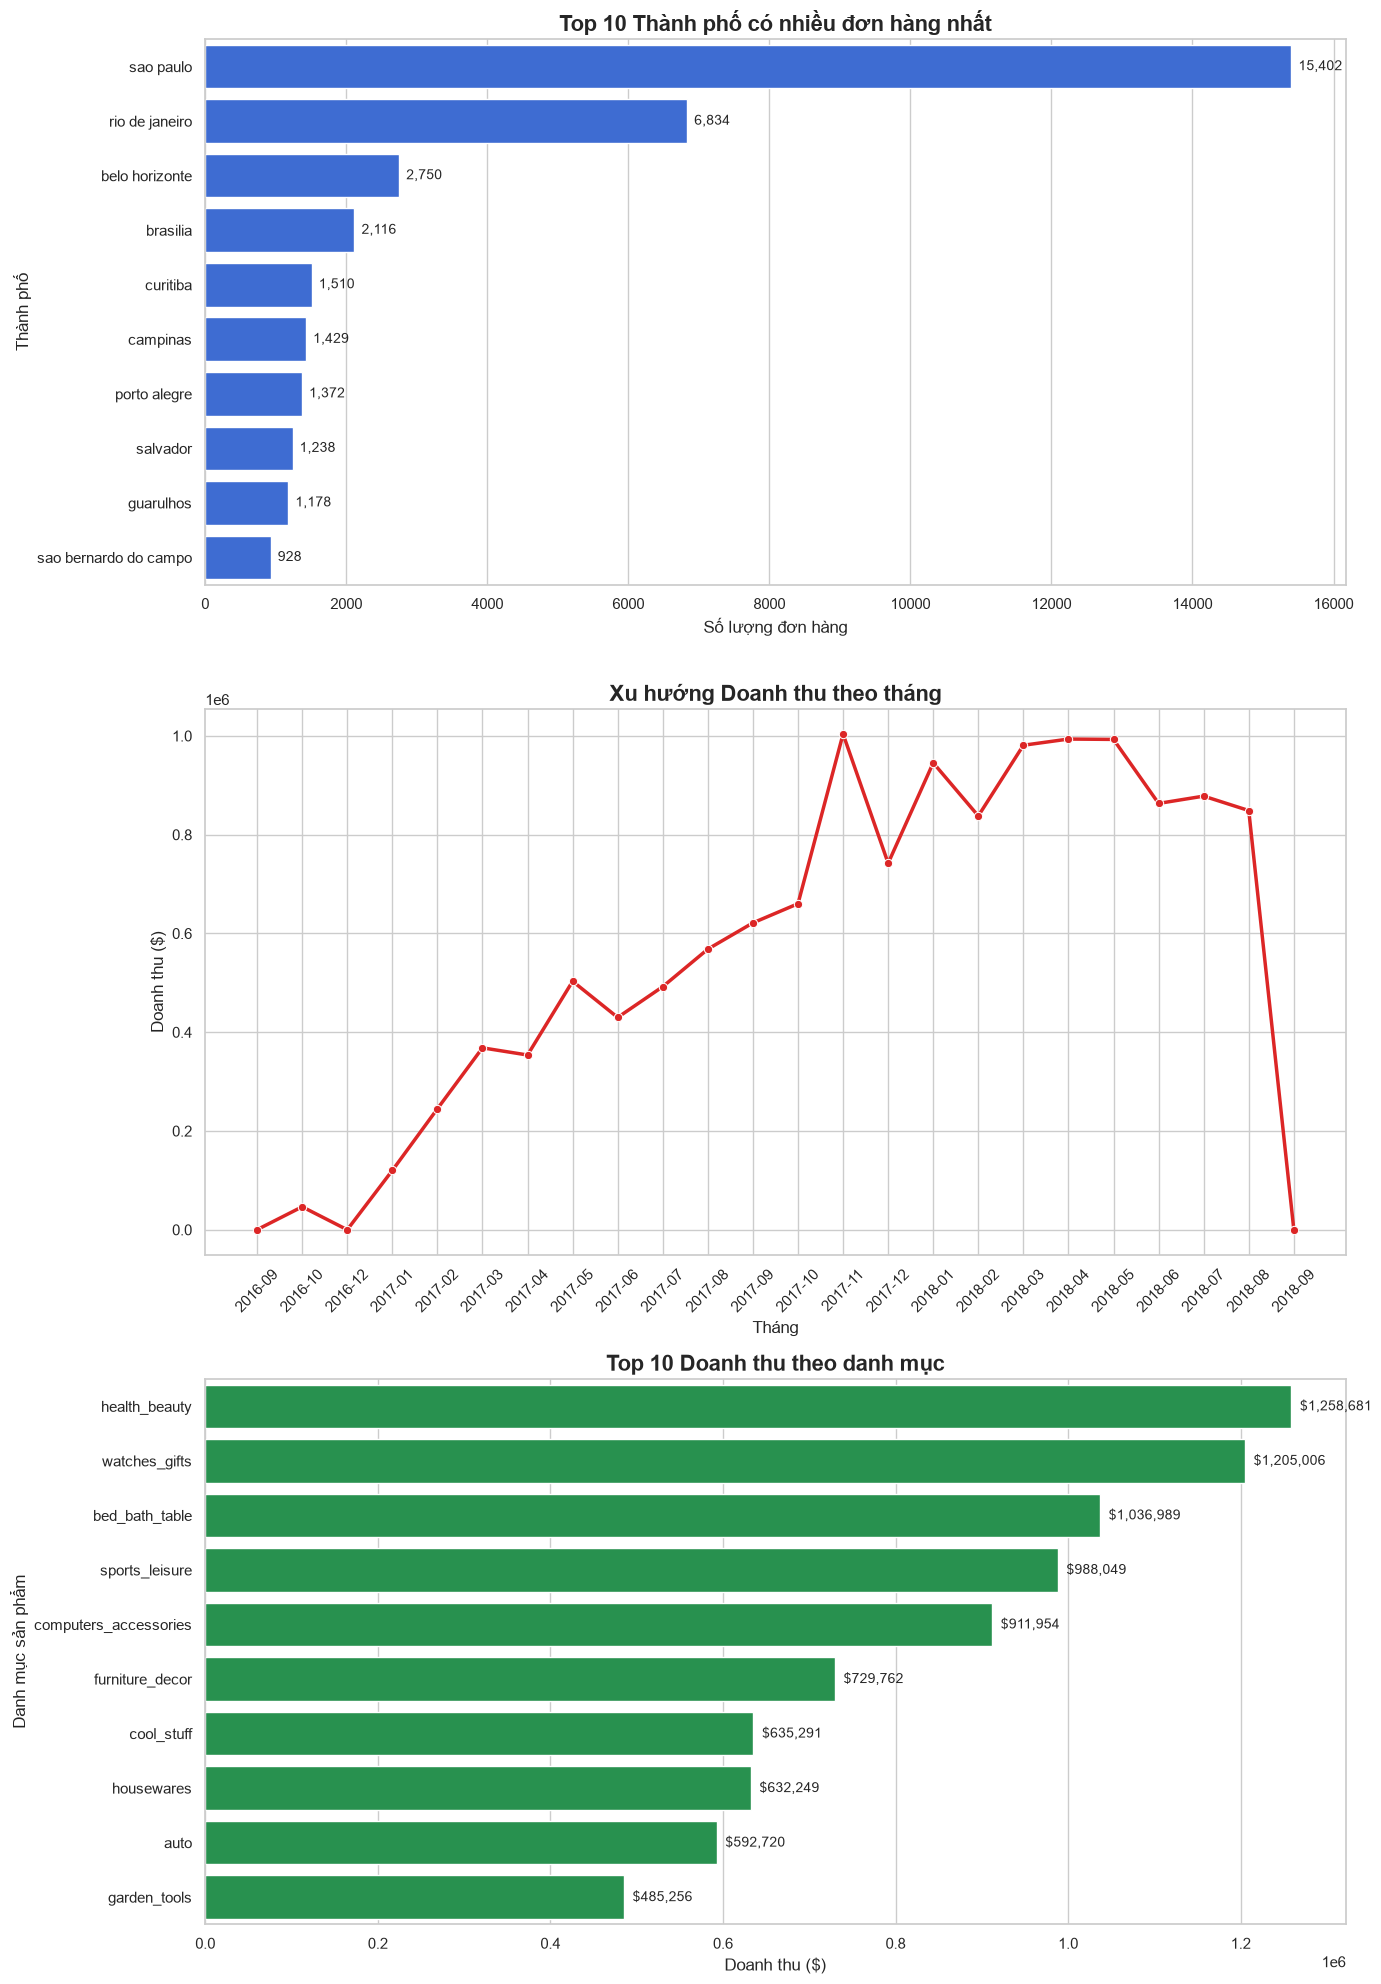

In [37]:
fig, axes = plt.subplots(3, 1, figsize=(14, 20))
fig.tight_layout(pad=8.0)

# 1. Top 10 thành phố có nhiều đơn hàng nhất
top_cities = (
    df_merged
    .groupby('customer_city')['order_id']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

sns.barplot(
    x=top_cities.values,
    y=top_cities.index,
    ax=axes[0],
    color='#2563EB'
)
axes[0].set_title('Top 10 Thành phố có nhiều đơn hàng nhất', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Số lượng đơn hàng')
axes[0].set_ylabel('Thành phố')
for i, v in enumerate(top_cities.values):
    axes[0].text(v + 100, i, f'{v:,}', va='center', fontsize=10)

# 2. Doanh thu theo tháng
succeeded_orders = df_merged[df_merged['order_status'] != 'canceled'].copy()
succeeded_orders['YearMonth'] = (
    succeeded_orders['order_purchase_timestamp']
    .dt.to_period('M')
    .astype(str)
)
monthly_revenue = (
    succeeded_orders
    .groupby('YearMonth')['price']
    .sum()
    .reset_index()
)

sns.lineplot(
    data=monthly_revenue,
    x='YearMonth',
    y='price',
    ax=axes[1],
    marker='o',
    color='#DC2626',
    linewidth=2.5
)
axes[1].set_title('Xu hướng Doanh thu theo tháng', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Tháng')
axes[1].set_ylabel('Doanh thu ($)')
axes[1].tick_params(axis='x', rotation=45)

# 3. Top 10 danh mục sản phẩm mang lại doanh thu cao nhất
top_categories = (
    df_merged
    .groupby('product_category_name')['price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_categories = top_categories.rename(
    index=lambda idx: category_translation.get(
        idx,
        idx.replace('_', ' ').title()
    )
)

sns.barplot(
    x=top_categories.values,
    y=top_categories.index,
    ax=axes[2],
    color='#16A34A'
)
axes[2].set_title('Top 10 Doanh thu theo danh mục', fontsize=16, fontweight='bold')
axes[2].set_xlabel('Doanh thu ($)')
axes[2].set_ylabel('Danh mục sản phẩm')
for i, v in enumerate(top_categories.values):
    axes[2].text(v + 10000, i, f'${v:,.0f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()
